<a href="https://colab.research.google.com/github/Bzamcho15/grade-calculator/blob/main/NBA_What_Predicts_Winning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Originally I had asked, "What factors in Basketball had the highest correlation to winning". Through my efforts I came to the conclusion that Among box-score stats, 2-point percentage (2P%) had the strongest correlation with wins (r = 0.64). Another thing to mention is that the Offensive Rating and Defensive Rating were about equally strong predictors (r ≈ 0.88 and −0.88). Scoring efficiently and preventing scores mattered about the same. One caveat in my research is that I only looked at data from the 25-26 NBA season and no others. Besides the fact that I based my data off one season, the biggest limitation is that correlation doesn't equal causation. Good teams tend to be good at everything so the stats rise together. This of course, can skew my data and not represent a more full picture of what actually determines winning. For a continuation, I could potentially add more Seasons or scan player level data to get an even more in-depth analysis on what factor influences winning the most.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/nba_project/nba_teams.csv")
df.head()
df.tail()

,Rk,Team,G,MP,FG,FGA,FG%,3P,3PA,3P%,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
26,27.0,Indiana Pacers,82,240.9,40.8,89.1,0.458,13.4,37.6,0.356,...,0.776,9.8,32.1,41.9,27.7,7.4,4.6,14.5,20.9,112.4
27,28.0,Sacramento Kings,82,240.9,41.6,89.0,0.467,10.3,30.2,0.340,...,0.772,11.5,30.8,42.3,25.5,8.0,4.5,14.3,19.7,111.0
28,29.0,Milwaukee Bucks,82,240.9,40.8,85.5,0.477,15.1,39.1,0.387,...,0.730,8.9,31.8,40.7,25.8,7.4,4.0,15.2,19.7,110.6
29,30.0,Brooklyn Nets,82,240.9,37.5,84.5,0.443,13.1,38.4,0.340,...,0.780,10.3,29.0,39.3,25.0,8.0,4.3,15.8,21.1,105.9
30,NaN,League Average,82,241.3,42.0,89.1,0.471,13.3,37.0,0.360,...,0.783,11.4,32.4,43.8,26.7,8.4,4.8,14.5,19.9,115.6


In [3]:
df = df[df["Team"] != "League Average"].copy()
df["Playoffs"] = df["Team"].str.contains("*", regex=False)
df["Team"] = df["Team"].str.replace("*","", regex=False)
df["Rk"] = df["Rk"].astype(int)
df.shape

(30, 26)

In [4]:
df.groupby("Playoffs")[["PTS", "3P%", "TRB", "AST", "TOV"]].mean()

,PTS,3P%,TRB,AST,TOV
Playoffs,,,,,
False,114.021429,0.356429,42.921429,26.657143,14.942857
True,116.993750,0.361875,44.500000,26.800000,14.143750


In [5]:
adv = pd.read_csv("/content/drive/MyDrive/nba_project/nba_advanced.csv", header=1)
adv.head()

,Rk,Team,Age,W,L,PW,PL,MOV,SOS,SRS,...,FT/FGA,Unnamed: 22,eFG%.1,TOV%.1,DRB%,FT/FGA.1,Unnamed: 27,Arena,Attend.,Attend./G
0,1.0,Oklahoma City Thunder*,25.2,64.0,18.0,65,17,11.15,-0.11,11.04,...,0.213,NaN,0.519,14.6,74.4,0.184,NaN,Paycom Center,764842,18203
1,2.0,San Antonio Spurs*,25.4,62.0,20.0,60,22,8.30,-0.03,8.28,...,0.215,NaN,0.522,11.5,77.3,0.180,NaN,Frost Bank Center,743129,18703
2,3.0,Detroit Pistons*,26.1,60.0,22.0,60,22,8.16,-0.63,7.53,...,0.223,NaN,0.517,14.8,74.2,0.251,NaN,Little Caesars Arena,806422,19651
3,4.0,Boston Celtics*,26.9,56.0,26.0,59,23,7.70,-0.33,7.37,...,0.167,NaN,0.523,11.4,75.7,0.189,NaN,TD Garden,785396,19156
4,5.0,New York Knicks*,28.1,53.0,29.0,56,26,6.33,-0.28,6.05,...,0.188,NaN,0.541,13.1,76.7,0.206,NaN,Madison Square Garden (IV),792480,19812


In [6]:
adv["Team"] = adv["Team"].str.replace("*", "", regex=False)
adv = adv[adv["Team"] != "League Average"]

cols = ["Team", "W", "L", "MOV", "ORtg", "DRtg", "NRtg"]
data = df.merge(adv[cols], on="Team")

In [7]:
data.shape

(30, 32)

In [8]:
data.corr(numeric_only=True)["W"].sort_values(ascending=False)

,W
W,1.000000
MOV,0.972603
NRtg,0.970968
ORtg,0.884938
Playoffs,0.824682
2P%,0.636865
PTS,0.631862
FG%,0.630381
FG,0.549201
TRB,0.516295


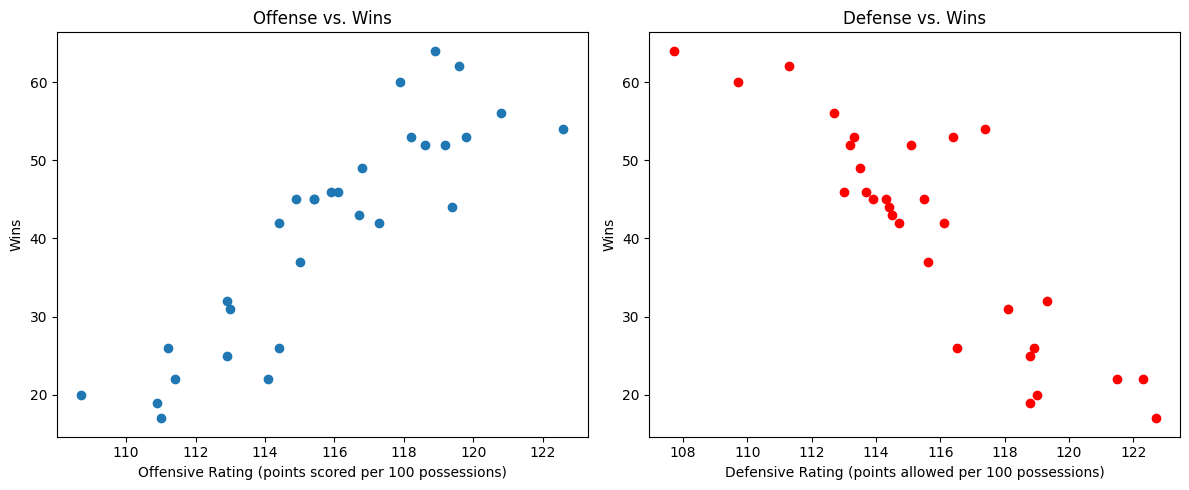

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(data["ORtg"], data["W"])
axes[0].set_xlabel("Offensive Rating (points scored per 100 possessions)")
axes[0].set_ylabel("Wins")
axes[0].set_title("Offense vs. Wins")

axes[1].scatter(data["DRtg"], data["W"], color="red")
axes[1].set_xlabel("Defensive Rating (points allowed per 100 possessions)")
axes[1].set_ylabel("Wins")
axes[1].set_title("Defense vs. Wins")

plt.tight_layout()
plt.show()